C:\Users\Admin\AppData\Local\Temp\ipykernel_8568\1978730775.py:244: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


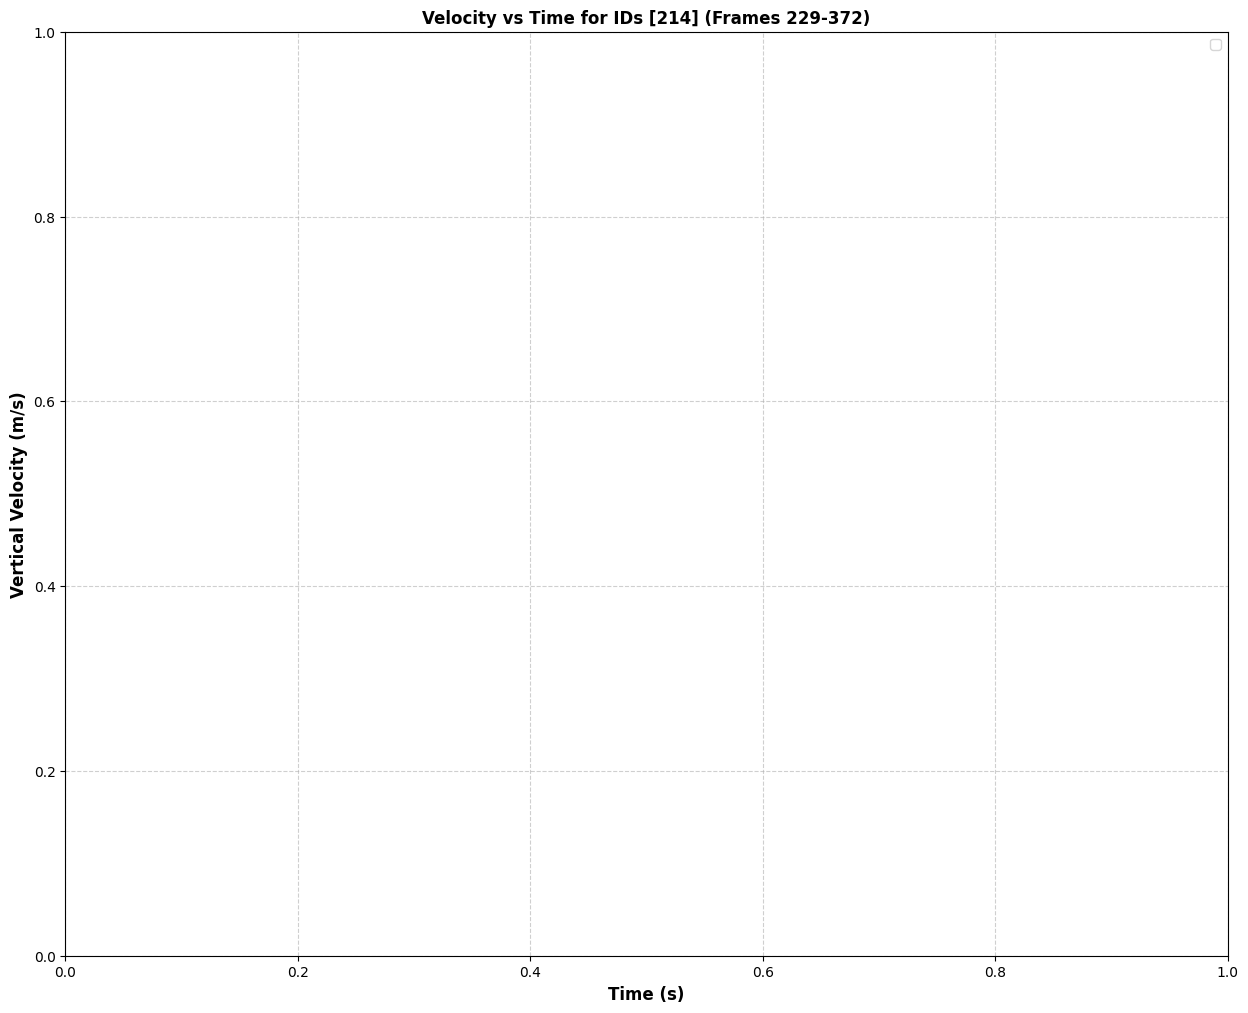

In [3]:
import cv2
import numpy as np
from tracker import EuclideanDistTracker            # Tracker to Track the obejcts from multiple video frames
import math
import matplotlib.pyplot as plt
import csv
import pandas as pd
import time

#Data for the Velocity
fps = 5000
frame_width_px = 640
frame_height_py= 480 
real_width_A = 53.5977  # In cm
real_height_A = 40.198  

meters_per_pixel_x = (real_width_A/100)/ frame_width_px
meters_per_pixel_y = (real_height_A/100)/frame_height_py

Tracking_id = range(0,300)     #We have enlisted some tracking ID's that we need to track. We store the values of the centeroids and frame indices in the disct to get them later.
centroids_values = {tid: [] for tid in Tracking_id} #We create the dict to store and arrange the values. tid " represents a specific id from the tracking id"
frame_indices_values = {tid: [] for tid in Tracking_id}
area_boul={tid:[] for tid in Tracking_id}
lk_points={tid:[] for tid in Tracking_id}
prev_gray= None # Acts as an rolling buffer and stores the i-1 frame of the analysis
points_per_id={}
offset_per_id={}
Tracker_ejecta= EuclideanDistTracker() #Calling the class "EuclideanDist Tracker" and Create tracker object( file in the same location as the py file)
feature_params=dict(maxCorners=50,qualityLevel=0.1,minDistance=3,blockSize=3) #selecting best 50 points after the quality inspection of each frame in (3x3 block)
lk_params=dict(winSize=(15,15),maxLevel=1,criteria=(cv2.TermCriteria_EPS|cv2.TermCriteria_COUNT,20,0.03))

video= cv2.VideoCapture(r"E:\Python Code\Boulder Detection Project\Data\Merengues-bowl_195bar_delrin_qs_vert.avi")
# object_d=cv2.createBackgroundSubtractorMOG2(1000,40,False)             #Detection of the objects 
object_d= cv2.createBackgroundSubtractorKNN(1000,400, False) # The algorithm to check the background and define the moving object.
c=0
frame_count=0
warmup_frames=50
fourcc=cv2.VideoWriter_fourcc(*'XVID')
out=cv2.VideoWriter(r"E:\Python Code\Boulder Detection Project\Output\Video_FV_Mask.avi",fourcc,10,(640,480),True)
while video.isOpened():
    r, frame= video.read()
    if not r:
        break
    h,w, _= frame.shape   
    gray= cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)  #Conversion to single tuple
    gray_blur=cv2.GaussianBlur(gray,(3,3),0)        # Not used in the code, trying to find an alternative.
    learning_rate=-1 if frame_count<warmup_frames else 0    #stabilizing the frame for KNN
    mask= object_d.apply(frame,learningRate=learning_rate)

    _, mask= cv2.threshold(mask, 254, 255, cv2.THRESH_BINARY)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3,3))
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel, iterations=1)  # remove specks and noise from the surrounding ejecta in mask
    mask = cv2.dilate(mask, kernel, iterations=2)  # fill gap or relax to make the normal shape of ejecta

    contours, _= cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    detection=[]
    for cnt in contours:
        area= cv2.contourArea(cnt)  
        if area<20 or area>20000:
            continue
        # The area selection starts after the countours of ejecta are being stored in the cnt varible and one by one go through the filter of area.
        x,y,w,h= cv2.boundingRect(cnt) #What if I directly get the centroid with out the rectangle?
        hull=cv2.convexHull(cnt)
        hull_area= cv2.contourArea(hull) if len(hull)>=3 else 1.0
        solidity= float(area)/hull_area if hull_area>0 else 0
        rect_area= float(w*h)
        extent= float(area)/rect_area if rect_area>0 else 0
        # print(f"area={area:.1f}, solidity={solidity:.2f}, E={extent:.2f}")

        if solidity<0.2:        #selection of round and convex material.
            continue
        if extent<0.15:
            continue
        detection.append([x,y,w,h])
        cv2.drawContours(frame, [cnt], -1, (0,255,0), 1)
# Beginning of Tracking from lucas-kanade optical method.
    if prev_gray is not None and len(points_per_id)>0:
        all_prev_pts_list=[]
        id_order=[]
        for tid, pts in points_per_id.items():      #Creates a pair of (tid, pts values)
            if pts is None or len(pts)==0:
                continue
            all_prev_pts_list.append(pts)
            id_order.append(tid)
        if len(all_prev_pts_list)==0:
            pass
        #The max corner points detected in the pixels for each id are being analyzed with the conditions. 
        # If there are points to be analyzed, they are arranged in a vertical stack to be analyzed and set as new points.
        else: 
            all_prev_pts_list=np.vstack(all_prev_pts_list).astype(np.float32)
            next_pts,status,err= cv2.calcOpticalFlowPyrLK(prev_gray,gray,all_prev_pts_list,None,**lk_params)
            if next_pts is None or status is None:
                points_per_id={tid:None for tid in Tracking_id}
            else:
                status=status.reshape(-1)
                points_per_id_new= {tid:None for tid in Tracking_id}
# The algorithm now initializes and starts the loop to assign the new points for the order id in tid.
                idx=0
                for tid in id_order:
                    old_pts= points_per_id[tid]
                    if old_pts is None or len(old_pts)==0:
                        continue                    
                    n= old_pts.shape[0] #The n value of the number of pts is known for each id. To get the number of points associated with the ID.
                    pts_id_new= next_pts[idx:idx+n] # temporary storage for each current frame 
                    stat_id=status[idx:idx+n]

                    good_new= pts_id_new[stat_id==1]

                    if len(good_new)>0:
                        points_per_id_new[tid]=good_new.reshape(-1,1,2)
                    else:
                        points_per_id_new[tid]=None
                    idx+=n
                points_per_id=points_per_id_new
# Detecting the object and checks the new position with the previous position of the frame.
    boxes_ids= Tracker_ejecta.update(detection)
    for x, y, w, h, id in boxes_ids:
        if id not in Tracking_id:
            continue
        x,y,w,h=int(x),int(y),int(w),int(h)
        cx_box = x + w/2.0
        cy_box = y + h/2.0
        if id in points_per_id and points_per_id[id] is not None and len(points_per_id[id])>0:
            pts= points_per_id[id].reshape(-1,2)
            lk_cx= float(np.mean(pts[:,0]))
            lk_cy=float(np.mean(pts[:,1]))
            cx=lk_cx
            cy=lk_cy
            for px,py in pts:
                cv2.circle(frame,(int(px),int(py)),1,(0,0,255),-1)
        else:
            cx=cx_box
            cy=cy_box

            roi_gray=gray[y:y+h,x:x+w]
            if roi_gray.size>0:
                features=cv2.goodFeaturesToTrack(roi_gray,mask=None,**feature_params)
            else:
                features=None
            if features is not None:
                features[:,0,0]+=x
                features[:,0,1]+=y
                points_per_id[id]=features
            else:
                points_per_id[id]=None
                cx=cx_box
                cy=cy_box
        cv2.rectangle(frame, (x, y), (x+w, y+h), (0,255,0), 1)
        cv2.putText(frame, str(id), (x, y-10), cv2.FONT_HERSHEY_PLAIN, 1, (255,0,0), 1)
        centroids_values[id].append((cx, cy))
        # print(f"ID:{id},Centroid:({cx},{cy})")
        frame_indices_values[id].append(frame_count)
        area_box=w*h
        area_boul[id].append(area_box)
    c=c+1
    frame_count+=1
    cv2.imshow("Mask", mask)
    cv2.imshow("Window", frame)
    # cv2.imwrite(r"E:\Python Code\Boulder Detection Project\Results\FV\MASK\Mask"+str(c)+".png",mask)
    # cv2.imwrite(r"E:\Python Code\Boulder Detection Project\Results\FV\CLR\Frame"+str(c)+".png",frame)
    out.write(mask)
    prev_gray=gray.copy()
    if cv2.waitKey(10) & 0xff==ord("z"):
        break
      
video.release()
out.release()
cv2.destroyAllWindows()

# Velocity, distance, time and frame determination of the individual ID's
distances_dict = {tid: [] for tid in Tracking_id}           # Making th dict to store the value of the data for each ID.
average_speed = {tid: [] for tid in Tracking_id}
time_dict = {tid: [] for tid in Tracking_id}
vx_dict={tid:[] for tid in Tracking_id}
vy_dict={tid:[] for tid in Tracking_id}
rows=[]

for tid in Tracking_id:
    centroids = centroids_values[tid]
    frames = frame_indices_values[tid]
    areas=area_boul[tid] 

    if len(centroids)<2:
        continue

    for i in range(1, len(centroids)):
        cx1, cy1 = centroids[i-1]
        cx2, cy2 = centroids[i]
        # Pixel differences
        dx_px = (cx2 - cx1)
        dy_px = (cy2 - cy1)

        # Convert to meters
        dx_m = dx_px * meters_per_pixel_x
        dy_m = dy_px * meters_per_pixel_y
        dt = (frames[i] - frames[i-1]) / fps

        if dt > 0:
            vx=dx_m/dt
            vy=(dy_m/dt)
            speed = math.hypot(vx,vy)
            distance=math.hypot(dx_m,dy_m)
            t_sec=(frames[i]/(fps))
            From_area=areas[i-1]
            to_area=areas[i]
            distances_dict[tid].append(distance)
            vx_dict[tid].append(vx)
            vy_dict[tid].append(vy)
            average_speed[tid].append(speed)
            time_dict[tid].append(t_sec)
            rows.append([tid, f"{frames[i-1]}",f"{frames[i]}",f"{From_area:.2f}",f"{cx1:.2f}",f"{cy1:.2f}",f"{to_area:.2f}",f"{cx2:.2f}",f"{cy2:.2f}",f"{dx_m:.4f}",f"{dy_m:.4f}",f"{distance:.4f}", f"{t_sec:.4f}", f"{vx:.2f}",f"{vy:.2f}",f"{speed:.2f}"])
            
timestamp=time.strftime("%Y%m%d_%H%M%S")
location=fr"E:\Python Code\Boulder Detection Project\Results\excel\frontview\data_{timestamp}.csv"

with open(location,mode='w', newline='') as f:
    writer=csv.writer(f,delimiter=';')
    writer.writerow(["ID","Frame_From","Frame_To","Area_1","Centroid_X1","Centroid_Y1","Area_2","Centroid_X2","Centroid_Y2","dx_m","dy_m","Distance(m)", "Time(s)", "vx(m/s)","vy(m/s)","speed(m/s)"])
    writer.writerows(rows)

stored_val = pd.read_csv(location, sep=";")
stored_val["ID"] = stored_val["ID"].astype(int)
stored_val["speed(m/s)"] = stored_val["speed(m/s)"].astype(float)
stored_val["vx(m/s)"] = stored_val["vx(m/s)"].astype(float)
stored_val["vy(m/s)"] = stored_val["vy(m/s)"].astype(float)
stored_val["Time(s)"] = stored_val["Time(s)"].astype(float)

frame_min, frame_max = 229,372
t_min,t_max= frame_min/fps, frame_max/fps
ids_to_plot = [214]

plt.figure(figsize=(15, 12))

for tid in ids_to_plot:
    df_filtered = stored_val[(stored_val["ID"] == tid) & (stored_val["Time(s)"] >= t_min) & (stored_val["Time(s)"] <= t_max)] 

    if not df_filtered.empty:
        plt.plot(df_filtered["Time(s)"], df_filtered["vy(m/s)"], marker='o', linestyle='-', color='royalblue',
         markersize=6, linewidth=2, markerfacecolor='orange', markeredgecolor='black', label=f"ID {tid}")
plt.xlabel("Time (s)",fontsize=12, fontweight='bold')
plt.ylabel("Vertical Velocity (m/s)",fontsize=12, fontweight='bold')
plt.title(f"Velocity vs Time for IDs {ids_to_plot} (Frames {frame_min}-{frame_max})",fontsize=12, fontweight='bold')
plt.grid(True,linestyle='--', alpha=0.6)
plt.legend()
plt.show()


In [ ]:
import cv2
import numpy as np
import math
import matplotlib.pyplot as plt
import csv
import pandas as pd
import time

location=fr"E:\Python Code\Boulder Detection Project\Output\Velocity Graph.xlsx"
stored_val = pd.read_excel(location)

stored_val["ID"]=stored_val["ID"].astype(int)
stored_val["R.Speed"] = stored_val["R.Speed"].astype(float)
stored_val["H.Velocity"] = stored_val["H.Velocity"].astype(float)
stored_val["V.Velocity"] = stored_val["V.Velocity"].astype(float)
stored_val["Time(s)"] = stored_val["Time(s)"].astype(float)
stored_val["Velocity Uncertainity(m/s)"]=stored_val["Velocity Uncertainity(m/s)"].astype(float)
fps= 5000
frame_min, frame_max = 50,1500

ids_to_plot = [1]
t_min,t_max= frame_min/fps, frame_max/fps
filtered_data = stored_val[(stored_val["Time(s)"] >= t_min) & (stored_val["Time(s)"] <= t_max)]
markers=['o','s','^','D','p','*']
plt.figure(figsize=(12, 8))

for i, tid in enumerate(ids_to_plot):
    df_tid = filtered_data[filtered_data["ID"] == tid]
    if not df_tid.empty:
        current_marker=markers[i % len(markers)]
        plt.errorbar(df_tid["Time(s)"], df_tid["V.Velocity"],yerr=df_tid["Velocity Uncertainity(m/s)"],marker=current_marker, fmt='o', ecolor='k',color='k',label=f"ID {tid}", markersize=10,fillstyle='none')
plt.xlabel("Time (s)", fontsize=12, fontweight='bold')
plt.ylabel("Vertical Velocity (m/s)", fontsize=12, fontweight='bold')
plt.title(f"Vertical Velocity vs Time for IDs {ids_to_plot}", fontsize=14, fontweight='bold')
plt.legend()
plt.show()

# for i, tid in enumerate(ids_to_plot):
#     df_tid = filtered_data[filtered_data["ID"] == tid]
#     if not df_tid.empty:
#         current_marker=markers[i % len(markers)]
#         plt.errorbar(df_tid["Time(s)"], df_tid["H.Velocity"],yerr=df_tid["Velocity Uncertainity(m/s)"],marker=current_marker, fmt='o', ecolor='k',color='k',label=f"ID {tid}", markersize=10,fillstyle='none')
# plt.xlabel("Time (s)", fontsize=12, fontweight='bold')
# plt.ylabel("Horizontal Velocity (m/s)", fontsize=12, fontweight='bold')
# plt.title(f"Horizontal Velocity vs Time for IDs {ids_to_plot}", fontsize=14, fontweight='bold')
# plt.legend()
# plt.show()

